# Exp 5 — Step-by-step Wasserstein Task Embeddings on a tiny MDP

Goal: make the LWE / WTE pipeline in `detect.py` fully inspectable.

We use a **2×2** `GridNavi` with **max_steps = 3**, a handful of transitions per goal, and a **tiny reference set** so every matrix (cost, transport plan, embedding map) is small enough to print.

**Pipeline (same as `Detect.lwe`):**
1. Collect SARS tuples `(s, a, r, s')` under a fixed goal (the *task*).
2. Preprocess: z-score states, one-hot actions → feature matrix `X ∈ R^{n × d}`.
3. Draw a shared random reference `R ∈ R^{m × d}`.
4. Cost `C_{ij} = ‖X_i − R_j‖₂²`.
5. Solve OT: transport plan `γ = EMD(unif(n), unif(m), C)`.
6. Barycentric map `f = (m · γᵀ X − R) / √m`, then flatten → embedding.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import ot
import torch
from matplotlib.patches import Rectangle

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
SCRIPTS_DIR = CODE_DIR / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from environments.gridworld import GridNavi
from detect import Detect

ACTION_NAMES = {0: "noop", 1: "up", 2: "right", 3: "down", 4: "left"}
np.set_printoptions(precision=3, suppress=True, linewidth=120)

## 1. Tiny MDP setup

- Grid: **2×2** (states `(0,0), (0,1), (1,0), (1,1)`)
- Episode length: **3** steps
- Sparse reward: `+1` on goal, else `-0.1` (paper-style)
- Tasks = goals. We exclude the all-zero start neighbourhood so goals are `(0,1), (1,0), (1,1)`.

In [2]:
NUM_CELLS = 2
MAX_STEPS = 3
STARTING_STATE = (0, 0)
OBS_DIM = 2
ACTION_DIM = 5  # noop, up, right, down, left
SEED = 0

# goals that GridNavi would allow with starting_state=(0,0) on a 2x2
TASKS = [(0, 1), (1, 0), (1, 1)]

print(f"states: {NUM_CELLS * NUM_CELLS}")
print(f"actions: {ACTION_DIM}  {ACTION_NAMES}")
print(f"max steps: {MAX_STEPS}")
print(f"tasks (goals): {TASKS}")

states: 4
actions: 5  {0: 'noop', 1: 'up', 2: 'right', 3: 'down', 4: 'left'}
max steps: 3
tasks (goals): [(0, 1), (1, 0), (1, 1)]


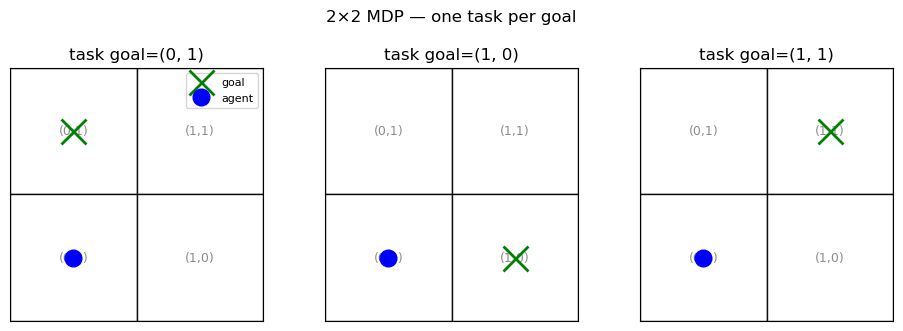

In [3]:
def draw_grid(ax, goal=None, agent=None, title=""):
    for x in range(NUM_CELLS):
        for y in range(NUM_CELLS):
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor="w", edgecolor="k", alpha=0.9))
            ax.text(x + 0.5, NUM_CELLS - y - 0.5, f"({x},{y})",
                    ha="center", va="center", fontsize=9, color="0.55")
    if goal is not None:
        gx, gy = goal
        ax.plot(gx + 0.5, NUM_CELLS - gy - 0.5, "gx", markersize=18, mew=2, zorder=5, label="goal")
    if agent is not None:
        ax_x, ax_y = agent
        ax.plot(ax_x + 0.5, NUM_CELLS - ax_y - 0.5, "bo", markersize=12, zorder=5, label="agent")
    ax.set_xlim(0, NUM_CELLS)
    ax.set_ylim(NUM_CELLS, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)

fig, axes = plt.subplots(1, len(TASKS), figsize=(3.2 * len(TASKS), 3.2))
for ax, goal in zip(axes, TASKS):
    draw_grid(ax, goal=goal, agent=STARTING_STATE, title=f"task goal={goal}")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("2×2 MDP — one task per goal", y=1.02)
plt.tight_layout()
plt.show()

## 2. Collect a small SARS dataset per task

For each goal we roll out random actions, starting from **every cell**, for `MAX_STEPS` steps.  
On a 2×2 with 3 steps that is only **4 × 3 = 12** transitions per task — small enough to print.

In [4]:
def collect_sars(goal, seed=SEED):
    """Collect (x, y, a, r, x', y') under sparse reward for one goal."""
    # deterministic seed from goal coords (avoid Python's salted hash())
    gx, gy = goal
    rng = np.random.default_rng(seed + 100 * gx + gy)
    rows = []
    for sx in range(NUM_CELLS):
        for sy in range(NUM_CELLS):
            env = GridNavi(
                num_cells=NUM_CELLS,
                num_steps=MAX_STEPS,
                starting_state=(sx, sy),
                distance_reward=False,  # sparse: -0.1 / +1
                possible_goals=TASKS,
            )
            env.reset_task(task=goal)
            obs, _ = env.reset()
            for _ in range(MAX_STEPS):
                a = int(rng.integers(0, ACTION_DIM))
                next_obs, r, terminated, truncated, _ = env.step(a)
                rows.append([obs[0], obs[1], a, r, next_obs[0], next_obs[1]])
                obs = next_obs
                if terminated or truncated:
                    break
    return np.asarray(rows, dtype=np.float32)


datasets = {g: collect_sars(g) for g in TASKS}

for g, sar in datasets.items():
    print(f"goal {g}: shape={sar.shape}  reward counts: "
          f"+1 → {(sar[:, 3] == 1.0).sum()},  -0.1 → {(np.isclose(sar[:, 3], -0.1)).sum()}")

print("\nExample rows for goal (1,1)  [x, y, a, r, x', y']:")
print(datasets[(1, 1)])

goal (0, 1): shape=(12, 6)  reward counts: +1 → 5,  -0.1 → 7
goal (1, 0): shape=(12, 6)  reward counts: +1 → 3,  -0.1 → 9
goal (1, 1): shape=(12, 6)  reward counts: +1 → 4,  -0.1 → 8

Example rows for goal (1,1)  [x, y, a, r, x', y']:
[[ 0.   0.   1.  -0.1  0.   1. ]
 [ 0.   1.   4.  -0.1  0.   1. ]
 [ 0.   1.   3.  -0.1  0.   0. ]
 [ 0.   1.   1.  -0.1  0.   1. ]
 [ 0.   1.   0.  -0.1  0.   1. ]
 [ 0.   1.   3.  -0.1  0.   0. ]
 [ 1.   0.   1.   1.   1.   1. ]
 [ 1.   1.   2.   1.   1.   1. ]
 [ 1.   1.   3.  -0.1  1.   0. ]
 [ 1.   1.   1.   1.   1.   1. ]
 [ 1.   1.   1.   1.   1.   1. ]
 [ 1.   1.   4.  -0.1  0.   1. ]]


In [5]:
# Pretty-print a few transitions for one task
goal_demo = (1, 1)
sar_demo = datasets[goal_demo]
print(f"Transitions for goal {goal_demo}:\n")
print(f"{'s':>8}  {'a':>6}  {'r':>5}  {'s_next':>8}")
print("-" * 36)
for row in sar_demo:
    s = (int(row[0]), int(row[1]))
    a = int(row[2])
    r = float(row[3])
    sp = (int(row[4]), int(row[5]))
    print(f"{str(s):>8}  {ACTION_NAMES[a]:>6}  {r:+5.1f}  {str(sp):>8}")

Transitions for goal (1, 1):

       s       a      r    s_next
------------------------------------
  (0, 0)      up   -0.1    (0, 1)
  (0, 1)    left   -0.1    (0, 1)
  (0, 1)    down   -0.1    (0, 0)
  (0, 1)      up   -0.1    (0, 1)
  (0, 1)    noop   -0.1    (0, 1)
  (0, 1)    down   -0.1    (0, 0)
  (1, 0)      up   +1.0    (1, 1)
  (1, 1)   right   +1.0    (1, 1)
  (1, 1)    down   -0.1    (1, 0)
  (1, 1)      up   +1.0    (1, 1)
  (1, 1)      up   +1.0    (1, 1)
  (1, 1)    left   -0.1    (0, 1)


## 3. Shared random reference

LWE embeds each empirical measure of transitions relative to a **fixed** reference set `R`.

Feature dim with SARS + one-hot actions:
$$
d = \underbrace{2}_{s} + \underbrace{5}_{a\text{ one-hot}} + \underbrace{1}_{r} + \underbrace{2}_{s'} = 10
$$

We take `m = REFERENCE_NUM = 4` reference points so the OT plan is `n × 4` and the embedding is length `4 × 10 = 40`.

In [6]:
REFERENCE_NUM = 4  # tiny on purpose
FEAT_DIM = OBS_DIM + ACTION_DIM + 1 + OBS_DIM  # s + a_oh + r + s'
EMBED_DIM = REFERENCE_NUM * FEAT_DIM

# same seed as Detect.set_reference (torch.manual_seed(98))
torch.manual_seed(98)
ref = torch.rand(REFERENCE_NUM, FEAT_DIM)

print(f"feature dim d = {FEAT_DIM}")
print(f"reference R shape = {tuple(ref.shape)}  (m={REFERENCE_NUM})")
print(f"embedding dim = m * d = {EMBED_DIM}")
print("\nReference R:")
print(ref.numpy())

feature dim d = 10
reference R shape = (4, 10)  (m=4)
embedding dim = m * d = 40

Reference R:
[[0.46  0.101 0.2   0.096 0.113 0.309 0.829 0.941 0.456 0.929]
 [0.441 0.184 0.471 0.214 0.029 0.749 0.407 0.603 0.133 0.921]
 [0.491 0.572 0.676 0.007 0.916 0.768 0.75  0.221 0.692 0.939]
 [0.24  0.363 0.31  0.018 0.455 0.171 0.742 0.276 0.381 0.246]]


## 4. Explicit LWE for one task (walk through every step)

We mirror `Detect.preprocess_dataset` + `Detect.lwe` with SARS flag, but print each intermediate.

In [7]:
def preprocess_sars(sar, normalize=True):
    """Match Detect.preprocess_dataset with sars_flag=True, one_hot=True."""
    X = torch.as_tensor(sar, dtype=torch.float32)
    state = X[:, :OBS_DIM]
    act = X[:, OBS_DIM]
    reward = X[:, OBS_DIM + 1].unsqueeze(1)
    next_state = X[:, -OBS_DIM:]

    if normalize:
        # Detect uses global mean/std over the whole state tensor (not per-dim)
        s_mean, s_std = state.mean(), state.std()
        ns_mean, ns_std = next_state.mean(), next_state.std()
        state = (state - s_mean) / s_std
        next_state = (next_state - ns_mean) / ns_std

    act_oh = torch.zeros(X.shape[0], ACTION_DIM)
    act_oh[torch.arange(X.shape[0]), act.long()] = 1.0

    return torch.cat([state, act_oh, reward, next_state], dim=1)


goal = (1, 1)
sar = datasets[goal]
X = preprocess_sars(sar)
n, d = X.shape
m = ref.shape[0]

print(f"Task goal = {goal}")
print(f"raw SARS shape: {sar.shape}")
print(f"preprocessed X shape: {X.shape}  (n={n}, d={d})")
print("\nX (first 6 rows):")
print(X[:6].numpy())
print("\ncolumn meaning: [sx, sy, a0..a4, r, s'x, s'y]")

Task goal = (1, 1)
raw SARS shape: (12, 6)
preprocessed X shape: torch.Size([12, 10])  (n=12, d=10)

X (first 6 rows):
[[-1.384 -1.384  0.     1.     0.     0.     0.    -0.1   -1.158  0.827]
 [-1.384  0.692  0.     0.     0.     0.     1.    -0.1   -1.158  0.827]
 [-1.384  0.692  0.     0.     0.     1.     0.    -0.1   -1.158 -1.158]
 [-1.384  0.692  0.     1.     0.     0.     0.    -0.1   -1.158  0.827]
 [-1.384  0.692  1.     0.     0.     0.     0.    -0.1   -1.158  0.827]
 [-1.384  0.692  0.     0.     0.     1.     0.    -0.1   -1.158 -1.158]]

column meaning: [sx, sy, a0..a4, r, s'x, s'y]


### 4a. Cost matrix

`ot.dist` defaults to squared Euclidean:
$$
C_{ij} = \|X_i - R_j\|_2^2 \in \mathbb{R}^{n \times m}
$$

C shape = (12, 4)  (n=12 samples × m=4 reference)

Cost matrix C:
[[10.963  9.531 14.317 10.386]
 [ 7.639  6.943  9.018  5.993]
 [13.025 10.571 13.367  8.768]
 [ 9.105  7.328 10.504  7.441]
 [ 8.896  6.814  9.166  6.857]
 [13.025 10.571 13.367  8.768]
 [ 4.066  4.74   7.94   6.168]
 [ 2.174  2.907  2.309  2.349]
 [ 7.208  6.117  6.485  4.166]
 [ 2.208  2.536  4.127  3.223]
 [ 2.208  2.536  4.127  3.223]
 [ 4.289  3.674  5.543  3.56 ]]


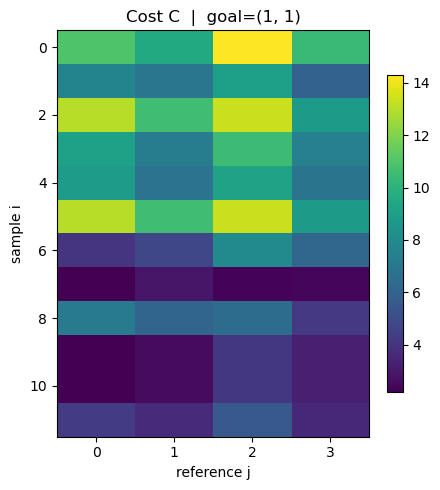

In [8]:
C = ot.dist(X.numpy(), ref.numpy())  # squared Euclidean by default
print(f"C shape = {C.shape}  (n={n} samples × m={m} reference)")
print("\nCost matrix C:")
print(C)

fig, ax = plt.subplots(figsize=(4.5, 5))
im = ax.imshow(C, aspect="auto", cmap="viridis")
ax.set_xlabel("reference j")
ax.set_ylabel("sample i")
ax.set_title(f"Cost C  |  goal={goal}")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### 4b. Optimal transport plan

Uniform marginals on samples and reference:
$$
a = \tfrac{1}{n}\mathbf{1}_n,\qquad b = \tfrac{1}{m}\mathbf{1}_m,\qquad
\gamma^\star = \arg\min_{\gamma\in\Pi(a,b)} \langle C, \gamma \rangle
$$
solved with the Earth Mover's Distance (`ot.emd`).

a (sample masses): [0.083 0.083 0.083 0.083] ... sum=1.000
b (ref masses):    [0.25 0.25 0.25 0.25]  sum=1.000

gamma shape = (12, 4)
Transport plan γ (rows=samples, cols=reference):
[[0.    0.083 0.    0.   ]
 [0.    0.    0.    0.083]
 [0.    0.    0.    0.083]
 [0.    0.083 0.    0.   ]
 [0.    0.083 0.    0.   ]
 [0.    0.    0.    0.083]
 [0.083 0.    0.    0.   ]
 [0.    0.    0.083 0.   ]
 [0.    0.    0.083 0.   ]
 [0.083 0.    0.    0.   ]
 [0.083 0.    0.    0.   ]
 [0.    0.    0.083 0.   ]]

row sums (should ≈ 1/n=0.0833): [0.083 0.083 0.083 0.083 0.083 0.083 0.083 0.083 0.083 0.083 0.083 0.083]
col sums (should ≈ 1/m=0.2500): [0.25 0.25 0.25 0.25]
⟨C, γ⟩ = W₂² cost = 5.8352


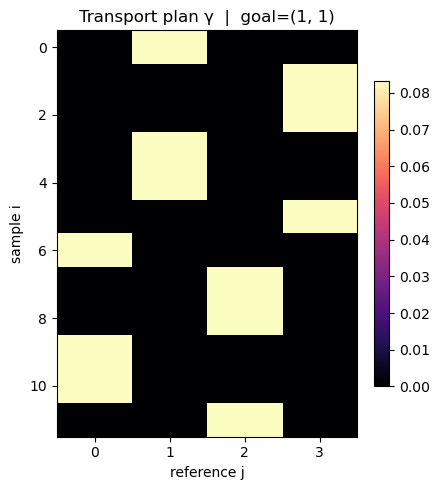

In [9]:
a = ot.unif(n)  # 1/n each
b = ot.unif(m)  # 1/m each
gamma = ot.emd(a, b, C)

print(f"a (sample masses): {a[:4]} ... sum={a.sum():.3f}")
print(f"b (ref masses):    {b}  sum={b.sum():.3f}")
print(f"\ngamma shape = {gamma.shape}")
print("Transport plan γ (rows=samples, cols=reference):")
print(gamma)
print(f"\nrow sums (should ≈ 1/n={1/n:.4f}): {gamma.sum(axis=1)}")
print(f"col sums (should ≈ 1/m={1/m:.4f}): {gamma.sum(axis=0)}")
print(f"⟨C, γ⟩ = W₂² cost = {(C * gamma).sum():.4f}")

fig, ax = plt.subplots(figsize=(4.5, 5))
im = ax.imshow(gamma, aspect="auto", cmap="magma")
ax.set_xlabel("reference j")
ax.set_ylabel("sample i")
ax.set_title(f"Transport plan γ  |  goal={goal}")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### 4c. Barycentric projection → embedding

Exactly as in `Detect.lwe`:
$$
f = \frac{m\,\gamma^\top X - R}{\sqrt{m}} \in \mathbb{R}^{m \times d}
$$
Then flatten to a vector of length `m · d`.

Intuition: for each reference point, `m · (γᵀ X)_j` is the mass-weighted barycenter of the samples that transport onto it; subtracting `R_j` gives a displacement field that characterises how this task's transitions sit relative to the shared reference.

In [10]:
gamma_t = torch.from_numpy(gamma).float()
X_t = X.float()

# step-by-step
bary = torch.matmul((m * gamma_t).T, X_t)   # (m, d)  weighted barycenters
f = (bary - ref) / np.sqrt(m)               # (m, d)  displacement field
embedding = f.ravel()                       # (m*d,)

print(f"bary (m·γᵀX) shape = {tuple(bary.shape)}")
print(bary.numpy())
print(f"\nf = (bary - R)/√m  shape = {tuple(f.shape)}")
print(f.numpy())
print(f"\nflattened embedding shape = {tuple(embedding.shape)}  (expected {EMBED_DIM})")
print("embedding:")
print(embedding.numpy())

bary (m·γᵀX) shape = (4, 10)
[[ 0.692 -0.     0.     1.     0.     0.     0.     1.     0.827  0.827]
 [-1.384 -0.     0.333  0.667  0.     0.     0.    -0.1   -1.158  0.827]
 [ 0.692  0.692  0.     0.     0.333  0.333  0.333  0.267  0.165  0.165]
 [-1.384  0.692  0.     0.     0.     0.667  0.333 -0.1   -1.158 -0.496]]

f = (bary - R)/√m  shape = (4, 10)
[[ 0.116 -0.051 -0.1    0.452 -0.057 -0.154 -0.415  0.03   0.186 -0.051]
 [-0.913 -0.092 -0.069  0.226 -0.014 -0.375 -0.203 -0.352 -0.646 -0.047]
 [ 0.101  0.06  -0.338 -0.004 -0.291 -0.217 -0.208  0.023 -0.263 -0.387]
 [-0.812  0.165 -0.155 -0.009 -0.227  0.248 -0.204 -0.188 -0.769 -0.371]]

flattened embedding shape = (40,)  (expected 40)
embedding:
[ 0.116 -0.051 -0.1    0.452 -0.057 -0.154 -0.415  0.03   0.186 -0.051 -0.913 -0.092 -0.069  0.226 -0.014 -0.375 -0.203
 -0.352 -0.646 -0.047  0.101  0.06  -0.338 -0.004 -0.291 -0.217 -0.208  0.023 -0.263 -0.387 -0.812  0.165 -0.155 -0.009
 -0.227  0.248 -0.204 -0.188 -0.769 -0.371]


### 4d. Sanity check vs `Detect.lwe`

Same reference seed → same numbers.

In [11]:
detect = Detect(
    reference_num=REFERENCE_NUM,
    input_dim=OBS_DIM,
    action_dim=ACTION_DIM,
    num_samples=None,  # use all rows; no subsampling
    sars_flag=True,
    normalized=True,
    one_hot=True,
)
detect.set_reference(OBS_DIM, REFERENCE_NUM, ACTION_DIM)

emb_lib = detect.lwe(sar, ACTION_DIM)
diff = (embedding - emb_lib).abs().max().item()
print(f"max |manual − Detect.lwe| = {diff:.2e}")
assert diff < 1e-5, "manual LWE does not match Detect.lwe"
print("OK — matches Detect.lwe")

max |manual − Detect.lwe| = 0.00e+00
OK — matches Detect.lwe


## 5. Embeddings for all tasks on this grid

Re-run the same explicit pipeline for every goal, with the **shared** reference.

In [12]:
def lwe_explicit(sar, reference):
    """Full explicit LWE; returns intermediates + embedding."""
    X = preprocess_sars(sar)
    n, d = X.shape
    m = reference.shape[0]
    C = ot.dist(X.numpy(), reference.numpy())
    gamma = ot.emd(ot.unif(n), ot.unif(m), C)
    gamma_t = torch.from_numpy(gamma).float()
    bary = torch.matmul((m * gamma_t).T, X.float())
    f = (bary - reference) / np.sqrt(m)
    emb = f.ravel()
    return {
        "X": X,
        "C": C,
        "gamma": gamma,
        "bary": bary,
        "f": f,
        "embedding": emb,
        "w2sq": float((C * gamma).sum()),
    }


results = {g: lwe_explicit(datasets[g], ref) for g in TASKS}

for g, res in results.items():
    e = res["embedding"].numpy()
    print(f"goal {g}:  ||emb||={np.linalg.norm(e):.3f}  "
          f"W₂²(X,R)={res['w2sq']:.3f}  emb[:8]={e[:8]}")

goal (0, 1):  ||emb||=1.650  W₂²(X,R)=5.587  emb[:8]=[-0.353  0.154 -0.1    0.119 -0.057 -0.154 -0.081  0.03 ]
goal (1, 0):  ||emb||=1.866  W₂²(X,R)=5.880  emb[:8]=[ 0.259 -0.214  0.066  0.119  0.11  -0.154 -0.415 -0.154]
goal (1, 1):  ||emb||=2.060  W₂²(X,R)=5.835  emb[:8]=[ 0.116 -0.051 -0.1    0.452 -0.057 -0.154 -0.415  0.03 ]


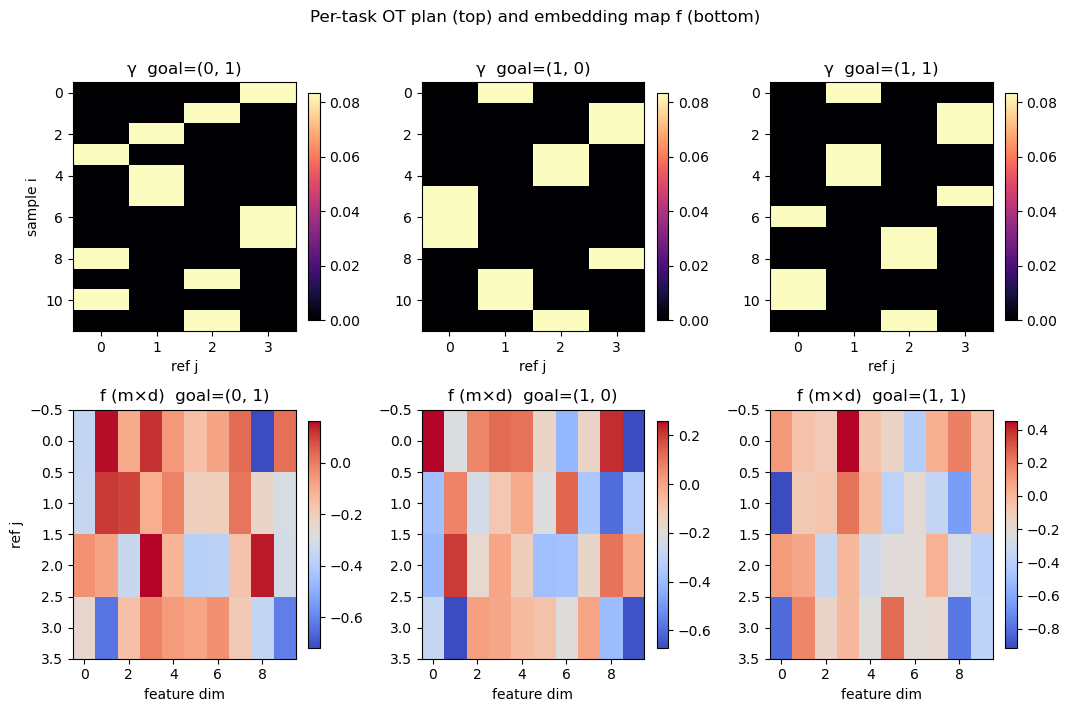

In [13]:
# Side-by-side: transport plans + displacement maps per task
fig, axes = plt.subplots(2, len(TASKS), figsize=(3.6 * len(TASKS), 7))

for col, g in enumerate(TASKS):
    res = results[g]
    im0 = axes[0, col].imshow(res["gamma"], aspect="auto", cmap="magma")
    axes[0, col].set_title(f"γ  goal={g}")
    axes[0, col].set_xlabel("ref j")
    if col == 0:
        axes[0, col].set_ylabel("sample i")
    plt.colorbar(im0, ax=axes[0, col], fraction=0.046)

    im1 = axes[1, col].imshow(res["f"].numpy(), aspect="auto", cmap="coolwarm")
    axes[1, col].set_title(f"f (m×d)  goal={g}")
    axes[1, col].set_xlabel("feature dim")
    if col == 0:
        axes[1, col].set_ylabel("ref j")
    plt.colorbar(im1, ax=axes[1, col], fraction=0.046)

fig.suptitle("Per-task OT plan (top) and embedding map f (bottom)", y=1.01)
plt.tight_layout()
plt.show()

## 6. Pairwise distances between task embeddings

On this tiny grid, goals that induce similar transition–reward statistics should land closer in embedding space.

L2 distances:
[[0.    1.739 1.98 ]
 [1.739 0.    1.843]
 [1.98  1.843 0.   ]]

cosine distances (1 − cos sim):
[[0.    0.484 0.552]
 [0.484 0.    0.437]
 [0.552 0.437 0.   ]]


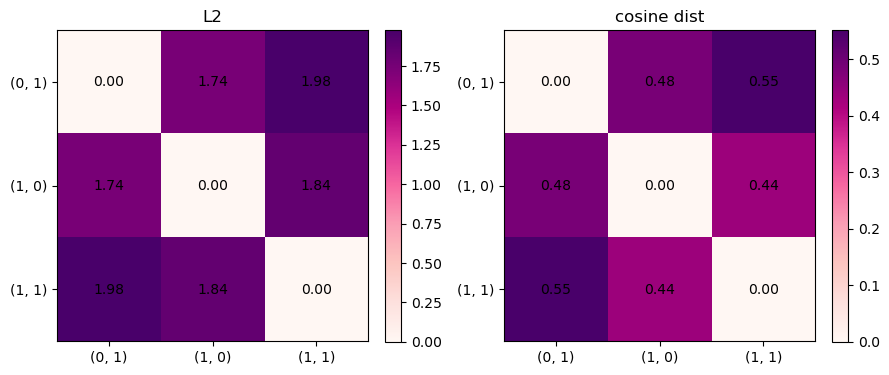

In [14]:
E = np.stack([results[g]["embedding"].numpy() for g in TASKS])
labels = [str(g) for g in TASKS]

# raw L2 and cosine distance
L2 = np.zeros((len(TASKS), len(TASKS)))
cos = np.zeros_like(L2)
En = E / np.linalg.norm(E, axis=1, keepdims=True)
for i in range(len(TASKS)):
    for j in range(len(TASKS)):
        L2[i, j] = np.linalg.norm(E[i] - E[j])
        cos[i, j] = 1.0 - float(En[i] @ En[j])

print("L2 distances:")
print(L2)
print("\ncosine distances (1 − cos sim):")
print(cos)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, title in zip(axes, [L2, cos], ["L2", "cosine dist"]):
    im = ax.imshow(M, cmap="RdPu")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    ax.set_title(title)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 7. Optional: bump to 3×3

Same math; only the state space grows. Still keep `MAX_STEPS` and `REFERENCE_NUM` small so matrices stay printable.

Set `RUN_3X3 = True` to execute.

In [15]:
RUN_3X3 = False  # flip to True to run

if RUN_3X3:
    NUM_CELLS_3 = 3
    MAX_STEPS_3 = 4
    TASKS_3 = [(0, 2), (1, 1), (2, 0), (2, 2)]  # corners + center

    def collect_sars_3(goal, seed=SEED):
        gx, gy = goal
        rng = np.random.default_rng(seed + 100 * gx + gy)
        rows = []
        for sx in range(NUM_CELLS_3):
            for sy in range(NUM_CELLS_3):
                env = GridNavi(
                    num_cells=NUM_CELLS_3,
                    num_steps=MAX_STEPS_3,
                    starting_state=(sx, sy),
                    distance_reward=False,
                    possible_goals=TASKS_3,
                )
                env.reset_task(task=goal)
                obs, _ = env.reset()
                for _ in range(MAX_STEPS_3):
                    a = int(rng.integers(0, ACTION_DIM))
                    next_obs, r, terminated, truncated, _ = env.step(a)
                    rows.append([obs[0], obs[1], a, r, next_obs[0], next_obs[1]])
                    obs = next_obs
                    if terminated or truncated:
                        break
        return np.asarray(rows, dtype=np.float32)

    datasets_3 = {g: collect_sars_3(g) for g in TASKS_3}
    results_3 = {g: lwe_explicit(datasets_3[g], ref) for g in TASKS_3}

    E3 = np.stack([results_3[g]["embedding"].numpy() for g in TASKS_3])
    E3n = E3 / np.linalg.norm(E3, axis=1, keepdims=True)
    D3 = 1.0 - E3n @ E3n.T

    print("3×3 cosine distances:")
    print(D3)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    labels3 = [str(g) for g in TASKS_3]
    im = ax.imshow(D3, cmap="RdPu")
    ax.set_xticks(range(len(labels3)))
    ax.set_yticks(range(len(labels3)))
    ax.set_xticklabels(labels3)
    ax.set_yticklabels(labels3)
    ax.set_title("3×3 cosine distances")
    for i in range(len(labels3)):
        for j in range(len(labels3)):
            ax.text(j, i, f"{D3[i, j]:.2f}", ha="center", va="center")
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()
else:
    print("Skipped. Set RUN_3X3 = True to embed a 3×3 grid the same way.")

Skipped. Set RUN_3X3 = True to embed a 3×3 grid the same way.


## Takeaways

1. A **task** here is just a goal: it only changes the reward column of SARS tuples; dynamics stay fixed.
2. LWE turns the empirical cloud of preprocessed transitions into a **displacement field** relative to a shared random reference via optimal transport.
3. Embedding dim = `REFERENCE_NUM × feature_dim`. With our toy settings that is `4 × 10 = 40` (vs `100 × 10 = 1000` in larger exps).
4. Everything above is exactly what `Detect.lwe` does — just with numbers small enough to read.